# 08 - Evaluation

In this notebook I compare the 5 models on the test year 2019.

- **RQ1:** Which model is most accurate?
- **RQ2:** How much worse does each model get from 1 hour ahead to 24 hours ahead?

### 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

forecast_folder = "../results/forecasts"
tables_folder = "../results/tables"
figures_folder = "../results/figures"

### 2. Load all forecasts into one table

In [2]:
files = {
    "Seasonal naive": "seasonal_naive.csv",
    "SARIMA": "sarima.csv",
    "XGBoost": "xgboost.csv",
    "LSTM": "lstm.csv",
    "PatchTST": "patchtst.csv",
}
models = list(files.keys())

first = pd.read_csv(forecast_folder + "/seasonal_naive.csv", parse_dates=["time", "cutoff"])
results = first[["time", "cutoff", "actual"]].copy()

for name, file in files.items():
    one = pd.read_csv(forecast_folder + "/" + file, parse_dates=["time", "cutoff"])
    results[name] = one["forecast"].values

# horizon = how many hours ahead (1 to 24)
results["horizon"] = ((results["time"] - results["cutoff"]).dt.total_seconds() / 3600).astype(int)

print("Rows:", len(results))
results.head()

Rows: 8760


,time,cutoff,actual,Seasonal naive,SARIMA,XGBoost,LSTM,PatchTST,horizon
0,2019-01-01 00:00:00,2018-12-31 23:00:00,27090.0,29173.0,26841.177488,25183.559,28542.621,26044.635,1
1,2019-01-01 01:00:00,2018-12-31 23:00:00,26958.0,27882.0,26046.684589,24707.264,27419.135,25328.918,2
2,2019-01-01 02:00:00,2018-12-31 23:00:00,24546.0,25943.0,24220.678164,23817.451,25752.668,23628.700,3
3,2019-01-01 03:00:00,2018-12-31 23:00:00,22100.0,24700.0,22320.167663,22702.140,24161.285,22324.533,4
4,2019-01-01 04:00:00,2018-12-31 23:00:00,21038.0,23836.0,21064.544063,21927.742,23209.855,21435.012,5


In [3]:
# check that every file has the same hours in the same order
for name, file in files.items():
    one = pd.read_csv(forecast_folder + "/" + file, parse_dates=["time"])
    assert (one["time"].values == results["time"].values).all(), name
print("All files match")

All files match


### 3. Remove the filled hours

In notebook 02, some hours in 2019 were wrong in the data and were filled. Their "actual" value is my own estimate, not the real load,
so I do not use them for scoring.

In [4]:
test = pd.read_csv("../datasets/processed/test.csv")
test["time"] = pd.to_datetime(test["time"]).dt.tz_localize(None)

results = results.merge(test[["time", "was_filled"]], on="time")
print("Filled hours removed:", results["was_filled"].sum())

results = results[results["was_filled"] == 0].reset_index(drop=True)
print("Hours used for scoring:", len(results))

Filled hours removed: 71
Hours used for scoring: 8689


### 4. Error measures

- **MAE**: average absolute error in MW
- **RMSE**: like MAE but big errors count more
- **MAPE**: average error in percent of the actual load
- **Skill**: how much better than the seasonal naive (in MAE). 0% = same as naive, 100% = perfect

In [5]:
def mae(actual, forecast):
    return np.mean(np.abs(actual - forecast))


def rmse(actual, forecast):
    return np.sqrt(np.mean((actual - forecast) ** 2))


def mape(actual, forecast):
    return np.mean(np.abs(actual - forecast) / actual) * 100

### 5. RQ1: Which model is most accurate?

In [6]:
rows = []
for name in models:
    rows.append([
        name,
        mae(results["actual"], results[name]),
        rmse(results["actual"], results[name]),
        mape(results["actual"], results[name]),
    ])

overall = pd.DataFrame(rows, columns=["model", "MAE", "RMSE", "MAPE"])

naive_mae = overall[overall["model"] == "Seasonal naive"]["MAE"].iloc[0]
overall["skill_vs_naive_%"] = (1 - overall["MAE"] / naive_mae) * 100

overall = overall.sort_values("MAE").reset_index(drop=True)
overall.to_csv(tables_folder + "/08_overall_results.csv", index=False)
overall.round(2)

,model,MAE,RMSE,MAPE,skill_vs_naive_%
0,XGBoost,1079.81,1411.77,3.29,45.38
1,LSTM,1138.61,1483.56,3.54,42.41
2,PatchTST,1246.02,1713.04,3.75,36.98
3,SARIMA,1845.25,2528.50,5.49,6.67
4,Seasonal naive,1977.04,2689.17,6.09,0.00


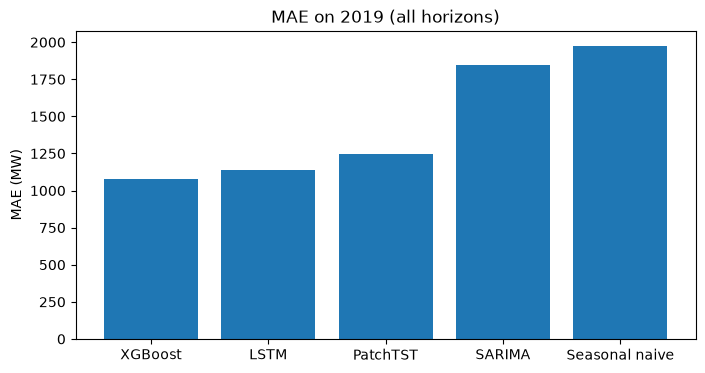

In [7]:
plt.figure(figsize=(8, 4))
plt.bar(overall["model"], overall["MAE"])
plt.title("MAE on 2019 (all horizons)")
plt.ylabel("MAE (MW)")
plt.savefig(figures_folder + "/08_overall_mae.png")
plt.show()

### 6. RQ2: Error by forecast horizon

In [8]:
rows = []
for h in range(1, 25):
    one_h = results[results["horizon"] == h]
    row = [h]
    for name in models:
        row.append(mae(one_h["actual"], one_h[name]))
    rows.append(row)

by_horizon = pd.DataFrame(rows, columns=["horizon"] + models)
by_horizon.to_csv(tables_folder + "/08_mae_by_horizon.csv", index=False)
by_horizon.round(0)

,horizon,Seasonal naive,SARIMA,XGBoost,LSTM,PatchTST
0,1,1749.0,443.0,545.0,1080.0,515.0
1,2,1807.0,713.0,738.0,1080.0,730.0
2,3,1861.0,909.0,810.0,1079.0,779.0
3,4,1994.0,1102.0,951.0,1116.0,952.0
4,5,2022.0,1291.0,1030.0,1085.0,1092.0
5,6,2192.0,2038.0,1198.0,1205.0,1385.0
6,7,2317.0,3251.0,1274.0,1226.0,1637.0
7,8,2297.0,3555.0,1179.0,1098.0,1664.0
8,9,2218.0,2931.0,1160.0,1155.0,1505.0
9,10,2169.0,2333.0,1172.0,1188.0,1442.0


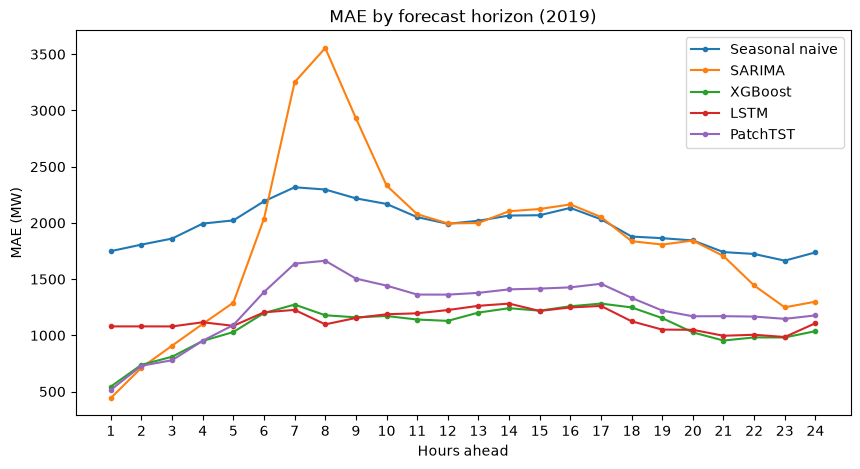

In [9]:
plt.figure(figsize=(10, 5))
for name in models:
    plt.plot(by_horizon["horizon"], by_horizon[name], marker="o", markersize=3, label=name)
plt.title("MAE by forecast horizon (2019)")
plt.xlabel("Hours ahead")
plt.ylabel("MAE (MW)")
plt.xticks(range(1, 25))
plt.legend()
plt.savefig(figures_folder + "/08_mae_by_horizon.png")
plt.show()

**Note:** every forecast starts at midnight (UTC), so "1 hour ahead" is always the hour 00:00-01:00 and "24 hours ahead" is always 23:00-24:00.
Part of the change with horizon therefore comes from the time of day (night hours are easier). The skill against the seasonal naive
below removes this effect, because the naive model has the same time of day at each horizon.

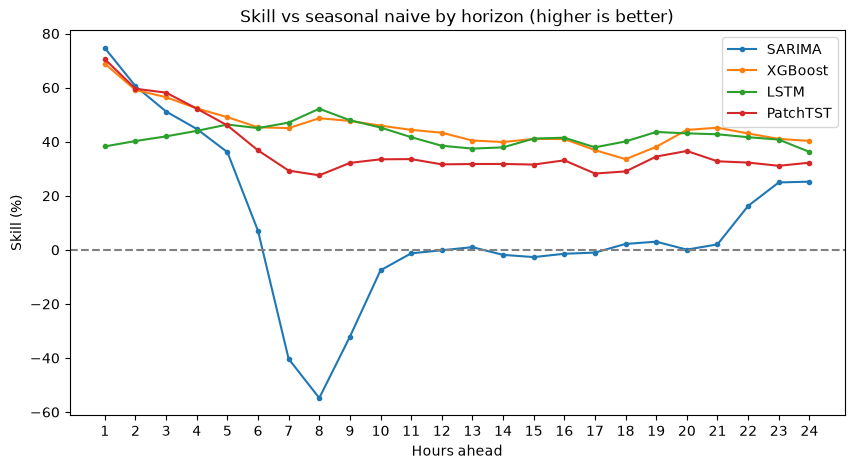

In [10]:
plt.figure(figsize=(10, 5))
for name in models:
    if name == "Seasonal naive":
        continue
    skill = (1 - by_horizon[name] / by_horizon["Seasonal naive"]) * 100
    plt.plot(by_horizon["horizon"], skill, marker="o", markersize=3, label=name)
plt.axhline(0, color="grey", linestyle="--")
plt.title("Skill vs seasonal naive by horizon (higher is better)")
plt.xlabel("Hours ahead")
plt.ylabel("Skill (%)")
plt.xticks(range(1, 25))
plt.legend()
plt.savefig(figures_folder + "/08_skill_by_horizon.png")
plt.show()

In [11]:
# 1 hour ahead vs 24 hours ahead
h1 = results[results["horizon"] == 1]
h24 = results[results["horizon"] == 24]

rows = []
for name in models:
    mape_1 = mape(h1["actual"], h1[name])
    mape_24 = mape(h24["actual"], h24[name])
    rows.append([name, mape_1, mape_24, mape_24 - mape_1])

h1_vs_h24 = pd.DataFrame(rows, columns=["model", "MAPE_1h", "MAPE_24h", "increase"])
h1_vs_h24.to_csv(tables_folder + "/08_h1_vs_h24.csv", index=False)
h1_vs_h24.round(2)

,model,MAPE_1h,MAPE_24h,increase
0,Seasonal naive,6.86,6.49,-0.37
1,SARIMA,1.70,4.90,3.20
2,XGBoost,2.07,4.01,1.94
3,LSTM,4.33,4.25,-0.09
4,PatchTST,1.96,4.43,2.47


### 7. Are the differences real? (Diebold-Mariano test)

The Diebold-Mariano test checks if two models really have different errors, or if the difference could be luck.
I compare the absolute errors of two models hour by hour. A p-value below 0.05 means the difference is significant.

I run it separately for 1 hour ahead and 24 hours ahead. There is one forecast per day for each horizon, so the 365 errors do not overlap.

In [12]:
def diebold_mariano(actual, forecast_a, forecast_b):
    # difference in absolute error, for each hour
    d = np.abs(actual - forecast_a) - np.abs(actual - forecast_b)
    dm = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
    p_value = 2 * (1 - stats.norm.cdf(abs(dm)))
    return dm, p_value

In [13]:
rows = []
for h in [1, 24]:
    one_h = results[results["horizon"] == h]
    for i in range(len(models)):
        for j in range(i + 1, len(models)):
            a = models[i]
            b = models[j]
            dm, p = diebold_mariano(one_h["actual"].values, one_h[a].values, one_h[b].values)
            if p < 0.05:
                better = a if dm < 0 else b
            else:
                better = "no significant difference"
            rows.append([h, a, b, round(dm, 2), round(p, 4), better])

dm_table = pd.DataFrame(rows, columns=["horizon", "model A", "model B", "DM", "p_value", "better model"])
dm_table.to_csv(tables_folder + "/08_diebold_mariano.csv", index=False)
dm_table

,horizon,model A,model B,DM,p_value,better model
0,1,Seasonal naive,SARIMA,15.39,0.0000,SARIMA
1,1,Seasonal naive,XGBoost,14.70,0.0000,XGBoost
2,1,Seasonal naive,LSTM,7.89,0.0000,LSTM
3,1,Seasonal naive,PatchTST,15.34,0.0000,PatchTST
4,1,SARIMA,XGBoost,-3.69,0.0002,SARIMA
5,1,SARIMA,LSTM,-11.21,0.0000,SARIMA
6,1,SARIMA,PatchTST,-3.07,0.0022,SARIMA
7,1,XGBoost,LSTM,-10.74,0.0000,XGBoost
8,1,XGBoost,PatchTST,1.52,0.1284,no significant difference
9,1,LSTM,PatchTST,11.11,0.0000,PatchTST


### 8. Training time

In [14]:
times = pd.concat([
    pd.read_csv(tables_folder + "/time_baselines.csv"),
    pd.read_csv(tables_folder + "/time_xgboost.csv"),
    pd.read_csv(tables_folder + "/time_deep.csv"),
])
times["seconds"] = times["seconds"].round(1)

summary = overall.merge(times, on="model")
summary.to_csv(tables_folder + "/08_summary.csv", index=False)
summary.round(2)

,model,MAE,RMSE,MAPE,skill_vs_naive_%,seconds
0,XGBoost,1079.81,1411.77,3.29,45.38,15.3
1,LSTM,1138.61,1483.56,3.54,42.41,67.1
2,PatchTST,1246.02,1713.04,3.75,36.98,294.5
3,SARIMA,1845.25,2528.50,5.49,6.67,156.4
4,Seasonal naive,1977.04,2689.17,6.09,0.00,0.0


Time = training + forecasting all of 2019 on my laptop. SARIMA includes the AutoARIMA search.

### 9. Forecasts for one week

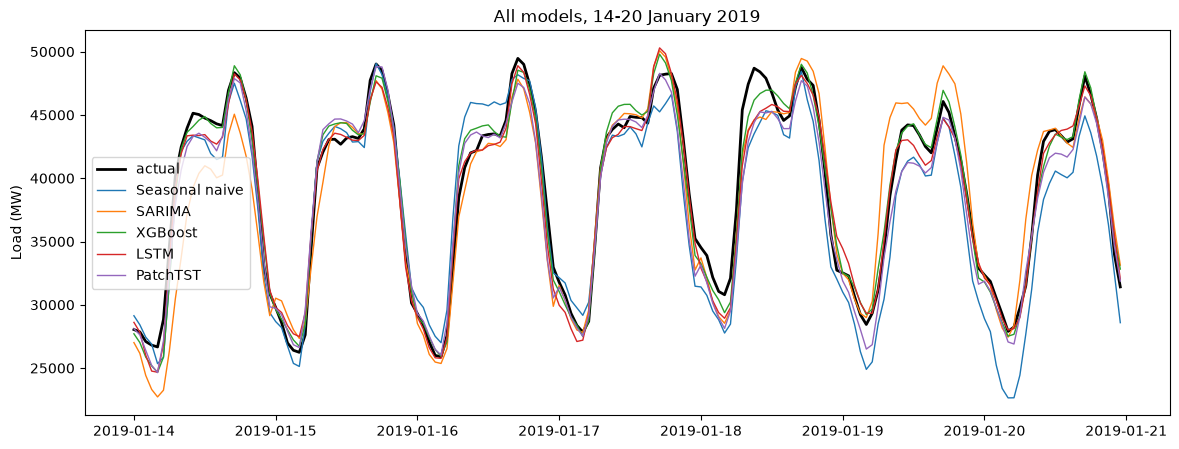

In [15]:
week = (results["time"] >= "2019-01-14") & (results["time"] < "2019-01-21")

plt.figure(figsize=(14, 5))
plt.plot(results[week]["time"], results[week]["actual"], label="actual", color="black", linewidth=2)
for name in models:
    plt.plot(results[week]["time"], results[week][name], label=name, linewidth=1)
plt.title("All models, 14-20 January 2019")
plt.ylabel("Load (MW)")
plt.legend()
plt.savefig(figures_folder + "/08_all_models_week.png")
plt.show()

### 10. Save the combined table for the next notebook

In [16]:
results.to_csv(forecast_folder + "/all_models.csv", index=False)
print("Saved")

Saved


### Summary

The tables above answer RQ1 (overall accuracy) and RQ2 (accuracy by horizon). All tables are saved in `results/tables/`.

**Next:** notebook 09 - where the models make their biggest mistakes (RQ3) and the feature ablation (RQ4).